
<div style="text-align:center;padding:40px 0 10px 0">

# 中小企业经营信贷的监管剖析

<br>

<div align="center">
<img src="汇报材料/目录.png"  width="700">
</div>

</div>
<hr>
<div style="font-size:10px;color:#666;">
参考文献：
    
1. 《中小银行中小企业信贷操作风险剖析与管控策略探究》https://max.book118.com/html/2026/0508/5002330142013211.shtm
2. 《我国商业银行中小企业信贷风险评估体系的深度剖析与优化路径》https://max.book118.com/html/2025/0727/6142145134011205.shtm

源码及免费文献入口：https://github.com/yyj2244413914/InternetFinancePresentation
</div>

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
import os
from pathlib import Path
for _d in [Path(os.getcwd()), *Path(os.getcwd()).parents]:
    if (_d / "src" / "data_access.py").exists():
        sys.path.insert(0, str(_d / "src"))
        break
from plot_style import setup, savefig, annotate_bars, PALETTE, C_MAIN, C_ACCENT, C_MID, C_LIGHT
setup()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
import data_access as da
print("环境就绪")

环境就绪


## 一、引言

### 1.1 研究背景与意义

在我国，根据《中华人民共和国中小企业促进法》和《中小企业划型标准规定》，中小企业划分为中型、小型、微型三种类型，具体标准根据企业从业人员、营业收入、资产总额等指标，结合行业特点制定。例如，工业企业中，从业人员 1000 人以下或营业收入 40000 万元以下的为中小微型企业。其中，从业人员 300 人及以上，且营业收入 2000 万元及以上的为中型企业；从业人员 20 人及以上，且营业收入 300 万元及以上的为小型企业；从业人员 20 人以下或营业收入 300 万元以下的为微型企业。批发业企业中，从业人员 200 人以下或营业收入 40000 万元以下的为中小微型企业，其中，从业人员 20 人及以上，且营业收入 5000 万元及以上的为中型企业；从业人员 5 人及以上，且营业收入 1000 万元及以上的为小型企业；从业人员 5 人以下或营业收入 1000 万元以下的为微型企业 。这种细致的划分标准，能够更精准地识别不同规模的企业，为政府制定针对性的扶持政策以及金融机构开展业务提供了明确依据。

<div align='center'>
    <img src="汇报材料/中小企业划分.png" width = 900>
</div>

### 1.1 研究背景与意义

在我国经济体系中，中小企业占据着举足轻重的地位，贡献了全国 **50% 以上的税收、60% 以上的 GDP、70% 以上的技术创新成果和 80% 以上的城镇劳动就业** ，已然成为推动经济增长、促进科技创新、稳定社会就业的关键力量。从经济增长角度来看，中小企业凭借其灵活的经营机制和创新活力，不断开拓新的市场领域，为经济发展注入源源不断的动力，在各个行业和领域中积极参与市场竞争，推动产业结构优化升级。在科技创新方面，中小企业往往更具创新精神和冒险意识，能够快速响应市场需求，开展技术研发和产品创新，许多新兴的技术和商业模式都源自中小企业的探索与实践。以**互联网科技领域**为例，众多中小企业在移动互联网、人工智能、大数据等前沿技术领域取得了突破性进展，成为推动行业发展的重要力量。在吸纳就业方面，中小企业数量众多、分布广泛，为不同层次的劳动力提供了丰富的就业机会，是缓解就业压力、促进社会稳定的重要支撑。从制造业到服务业，从传统行业到新兴产业，中小企业都吸纳了大量的劳动力，为保障民生、促进社会和谐做出了重要贡献。

<div align='center'>
<img src="汇报材料/发展指数2.png" width="300"><img src="汇报材料/中小企业发展指数.png" width="300">
    </div>

### 1.1 研究背景与意义

然而，中小企业在发展过程中面临着诸多挑战，其中融资难问题尤为突出。由于中小企业自身规模较小、抵押物不足、财务制度不够健全、抗风险能力较弱等原因，其在获取外部资金支持时面临着较大的困难。商业银行作为中小企业融资的主要渠道之一，对中小企业的信贷支持对于缓解其融资困境、促进其健康发展至关重要。近年来，随着国家政策的引导和市场竞争的加剧，商业银行逐渐加大了对中小企业信贷业务的投入力度。例如，央行通过再贷款、再贴现等货币政策工具，引导商业银行增加对中小企业的信贷投放；银保监会也出台了一系列政策措施，鼓励商业银行创新信贷产品和服务模式，提高对中小企业的金融服务水平。

尽管商业银行在支持中小企业发展方面做出了积极努力，但中小企业信贷业务仍面临着较高的风险。中小企业经营稳定性相对较差，易受到市场波动、经济周期、行业竞争等因素的影响，导致其还款能力和还款意愿存在较大不确定性。据相关数据显示，部分行业的中小企业贷款不良率明显高于大型企业，这给商业银行的资产质量和经营效益带来了一定压力。中小企业财务信息不透明、信用体系不完善等问题，也增加了商业银行对其信用风险评估的难度，使得商业银行在信贷决策过程中面临较大的信息不对称风险。
<div align='center'>
<img src="汇报材料/融资难.png" width="300"><img src="汇报材料/存活周期.png" width="300">
</div>

因此，从**监管视角**剖析中小企业经营信贷问题并以此开展信贷风险评估，具有直接的理论与现实意义。

## 二、中小企业信贷监管流程

### 信贷监管流程总览：贷前 → 审批 → 发放 → 贷后

中小银行中小企业信贷业务是一条完整链条，四个环节**首尾相连、层层把关**：

> **① 贷前调查 → ② 贷款审批 → ③ 贷款发放 → ④ 贷后管理**

<div align='center'>
    <img src="汇报材料/流程.jpg" width=500>
</div>

后文的监管处罚数据会反复回到这四段——违规主要集中在**“贷前”与“贷后”**，即**“没看清企业”**与**“没跟住企业”**。

#### ① 贷前调查：把企业“看清楚”

目的：全面掌握企业的**基本、经营、财务、信用**四类状况，为贷款决策提供依据。

在实际操作中，调查人员会首先与企业进行沟通，收集企业的营业执照、税务登记证、组织机构代码证等基本资料，以核实企业的合法经营资格和存续状态。同时，详细了解企业的股权结构、股东背景及相互关系，判断企业的治理结构是否合理，是否存在潜在的关联交易风险。对于企业的实际控制人，调查人员会关注其个人信用记录、从业经历、经营能力等，因为实际控制人的个人素质和能力对企业的发展有着至关重要的影响。

在了解企业基本信息后，调查人员会重点考察企业的经营状况。实地走访企业的生产经营场所，观察企业的生产设备是否先进、运行是否正常，了解企业的生产规模、生产工艺以及产品质量等情况。与企业的管理层和员工进行交流，了解企业的经营理念、管理模式、市场开拓能力以及员工的工作积极性和稳定性。通过对企业上下游客户的调查，了解企业的市场地位、产品销售情况、供应链稳定性以及应收账款回收情况等，评估企业在市场中的竞争力和经营的可持续性。

财务状况调查是贷前调查的核心内容之一。调查人员会仔细审查企业的财务报表，包括资产负债表、利润表、现金流量表等，分析企业的资产规模、资产结构、负债水平、盈利能力、偿债能力以及资金流动性等指标。关注企业财务数据的真实性和合理性，通过与企业的银行对账单、税务申报表等资料进行比对，核实财务数据的准确性。同时，运用财务分析方法，如比率分析、趋势分析、结构分析等，深入挖掘企业财务状况背后的潜在问题，判断企业的财务健康状况和还款能力。

<div align='center'>
    <img src="汇报材料/腾讯报表1.png" width=300><img src="汇报材料/腾讯报表2.png" width=300>
</div>

#### ① 贷前调查：把企业“看清楚”

信用状况调查也是不可或缺的环节。调查人员会查询企业的征信报告，了解企业的贷款记录、还款情况、逾期记录等，评估企业的信用风险。向其他金融机构、供应商、合作伙伴等了解企业的信用口碑和商业信誉，全面掌握企业的信用状况。对于有担保的贷款，还会对担保人的资质、担保能力以及抵押物的价值、权属、变现能力等进行调查和评估，确保担保措施的有效性和可靠性。

<div align='center'>
    <img src="汇报材料/企业征信报告.jpg" width=400>
</div>

#### ② 贷款审批：把风险“评准确”

目的：在贷前调查的基础上，对贷款申请进行**综合评估和决策的过程**。

<div align='center'>
    <img src="汇报材料/审批流程.png" width=500>
</div>

审批人员会依据银行的信贷政策、风险偏好以及内部制定的审批标准，对贷款申请进行严格审查。首先，对贷前调查提供的资料进行复核，确保资料的完整性、真实性和准确性。重点审查企业的贷款用途是否合规、合理，是否符合国家产业政策和银行的信贷投向要求。例如，对于高污染、高耗能的中小企业贷款申请，银行可能会严格限制或拒绝，以响应国家的环保政策和产业结构调整要求。

审批人员会运用风险评估模型和工具，对企业的信用风险、市场风险、经营风险等进行量化评估。根据企业的财务指标、信用记录、行业前景等因素，计算出企业的违约概率和违约损失率，确定贷款的风险等级。同时，综合考虑银行的资金成本、市场利率水平、贷款期限等因素，确定合理的贷款利率、贷款额度和还款方式。例如，对于风险等级较高的企业，银行可能会提高贷款利率，降低贷款额度，要求更严格的还款方式，如缩短还款期限、采用等额本金还款方式等，以补偿风险和确保贷款的安全回收。

在审批过程中，通常会实行分级审批制度。根据贷款金额的大小和风险程度，由不同层级的审批人员或审批委员会进行审批。对于小额、低风险的贷款，可能由基层信贷部门的负责人直接审批；对于大额、高风险的贷款，则需要提交到银行的信贷审批委员会进行集体审议和决策。审批委员会由银行的风险管理部门、信贷业务部门、法律合规部门等相关人员组成，他们会从不同角度对贷款申请进行分析和评估，确保审批决策的科学性和公正性。



#### ③ 贷款发放：把手续“办合规”

目的：在贷款审批通过后，将**贷款资金发放到企业账户**的过程。

银行会与企业签订借款合同和相关担保合同，明确双方的权利和义务。借款合同中会详细规定贷款金额、贷款期限、贷款利率、还款方式、违约责任等条款，担保合同则会对担保方式、担保范围、担保期限等进行约定。合同签订前，银行会对合同条款进行严格审查，确保合同内容合法、合规、完整，避免出现法律漏洞和风险隐患。

合同签订后，银行会按照合同约定的条件和程序，落实担保手续。对于抵押担保，会办理抵押物的登记手续，确保银行对抵押物享有合法的优先受偿权；对于质押担保，会办理质押物的交付或登记手续，确保质押物的安全和有效控制。同时，银行会对贷款资金的用途进行监控，要求企业提供贷款资金使用计划和相关的交易合同、发票等凭证，确保贷款资金按照约定的用途使用，防止贷款资金被挪用。在确认所有手续完备后，银行会将贷款资金发放到企业指定的账户，完成贷款发放流程。

<div align='center'>
    <img src="汇报材料/发贷款.jpg" width=400>
</div>

#### ④ 贷后管理：把钱“收回来”

目的：是信贷业务流程的**最后一个环节**，也是**确保贷款安全回收**的重要环节。

贷后管理主要包括对企业的持续跟踪、风险监测、还款管理以及贷款回收等工作。

<div align='center'>
    <img src="汇报材料/贷后流程.jpg" width=500>

#### ④ 贷后管理：把钱“收回来”

信贷人员会定期对企业进行实地走访，了解企业的经营状况是否发生变化，如生产经营是否正常、市场销售是否顺畅、管理层是否稳定等。关注企业的财务状况，要求企业定期提供财务报表，分析企业的财务指标变化情况，及时发现潜在的财务风险。例如，若企业的应收账款周转率大幅下降，可能意味着企业的销售回款出现问题，存在资金链断裂的风险。

<div align='center'>
    <img src="汇报材料/帮忙2.jpg" width=400><img src="汇报材料/银行帮忙.png" width=200>
</div>


#### ④ 贷后管理：把钱“收回来”

<div align='center'>
    <img src="汇报材料/风险监测.png" width = 400>
</div>

风险监测是贷后管理的核心任务之一。银行会建立风险预警机制，运用大数据分析、风险监测模型等技术手段，对企业的各类风险指标进行实时监测和分析。当风险指标超过预设的阈值时，系统会自动发出预警信号，提示信贷人员关注。预警信号可能包括企业的逾期还款、财务指标恶化、行业风险上升、市场环境变化等情况。信贷人员在收到预警信号后，会及时进行调查和分析，采取相应的风险控制措施，如要求企业增加担保措施、提前收回部分贷款、调整还款计划等，以降低贷款风险。


还款管理也是贷后管理的重要内容。信贷人员会在贷款到期前，提前通知企业做好还款准备，提醒企业按时足额还款。对于还款困难的企业，信贷人员会与企业进行沟通，了解企业的还款困难原因，帮助企业制定合理的还款计划。如果企业确实无法按时还款，银行会根据具体情况，按照相关规定和合同约定，采取相应的催收措施，如电话催收、上门催收、发送催收函、法律诉讼等，以确保贷款资金的回收。


在贷款回收后，银行会对信贷业务进行总结和评估，分析贷款业务的风险控制情况、收益情况以及存在的问题和不足，为今后的信贷业务提供经验教训和改进方向。同时，对企业的信用记录进行更新和维护，为企业的后续融资提供参考依据 。

## 三、中小企业信贷风险评估

商业银行在对中小企业信贷风险进行评估时，运用了多种方法，这些方法各有特点，在不同的场景和条件下发挥着重要作用。

<div align='center'>
    <img src="汇报材料/风险评估.png" width=500>
</div>

### 3.1 信贷风险评估方法

**专家评估法**是一种较为传统的信贷风险评估方法，它主要依赖于经验丰富的信贷专家的专业知识和主观判断。在实际操作中，专家会全面考量中小企业的多个方面因素。

在信用历史方面，专家会详细审查企业以往的贷款还款记录，是否存在逾期还款、欠款不还等不良信用行为。

对于财务状况，专家不仅会分析企业的资产负债表、利润表、现金流量表等财务报表，计算资产负债率、流动比率、利润率等关键财务指标，还会关注财务数据的真实性和稳定性。

在经营状况上，专家会考察企业的市场竞争力、产品或服务的市场需求、生产运营效率等。专家还会考虑企业的发展前景、行业趋势、宏观经济环境等因素对企业未来还款能力的影响。

虽然专家评估法能够充分利用专家的经验和知识，对一些难以量化的因素进行综合判断，在处理复杂或特殊情况时具有一定的灵活性和优势。但该方法也存在明显的局限性，其准确性在很大程度上取决于专家的专业水平、经验丰富程度和个人判断能力，不同专家对同一企业的评估结果可能存在较大差异，主观性较强，一致性难以保证。

<div align='center'>
    <img src="汇报材料/专家评分.png" width=500>
</div>


### 3.1 信贷风险评估方法

**信用评分法**是一种基于统计原理的风险评估方法，具有较强的客观性和量化性。它通过对中小企业的信用历史、财务状况、经营状况等多个因素进行系统分析，利用数学算法为每个因素赋予相应的权重，最终计算得出一个综合的信用评分。在信用历史方面，会考虑企业过去的贷款违约情况、信用卡还款记录等，若企业信用记录良好，违约次数少，在信用评分中会获得较高的分值。财务状况因素中，资产负债率、流动比率、营业收入增长率等财务指标会被纳入评分体系，资产负债率低、流动比率合理、营业收入增长稳定的企业，信用评分会相对较高。经营状况方面，企业的市场份额、客户满意度、员工稳定性等因素也会影响信用评分。某中小企业市场份额逐年扩大，客户满意度高，员工流动率低，说明其经营状况良好，信用评分会得到提升。信用评分越高，通常意味着企业的信用风险越低。这种方法能够快速、客观地评估大量中小企业的风险状况，为商业银行的信贷决策提供较为客观的依据，提高了信贷审批的效率和一致性。然而，信用评分法的准确性高度依赖于数据的质量和完整性。若数据存在错误、缺失或不真实的情况，会导致评分结果出现偏差，影响风险评估的准确性。信用评分模型的构建和参数设定也需要大量的历史数据和专业的统计分析知识，模型的更新和调整相对复杂，难以及时适应市场环境和企业经营状况的快速变化。

<div align='center'>
    <img src="汇报材料/信用评分链路.png" width=500>
</div>

### 3.1 信贷风险评估方法

**统计分析法**是通过对大量历史数据的统计分析，来揭示数据背后的规律和趋势，从而评估中小企业信贷风险的方法。常用的统计分析方法包括判别分析、主成分分析、Logistic 回归分析等。判别分析可以根据已知的样本数据，建立判别函数，将中小企业划分为不同的风险类别，如低风险、中风险、高风险。主成分分析则是通过降维的方式，将多个相关的财务指标和非财务指标转化为少数几个互不相关的综合指标，即主成分，这些主成分能够反映原始数据的大部分信息，从而简化数据结构，便于分析和评估风险。

<div align='center'>
    <img src="汇报材料/PCA.jpg" width=350><img src="汇报材料/对率回归.png" width=200>
</div>

### 3.2 信贷风险度量模型

随着金融市场的发展和风险管理需求的不断提高，商业银行在信贷风险评估中运用了多种先进的度量模型，这些模型各有其独特的原理、应用场景和优缺点，为商业银行准确评估中小企业信贷风险提供了有力的工具。

<div align='center'>
    <img src="汇报材料/度量模型.jpg" width=400>
</div>


### 3.2 信贷风险度量模型

CreditMetrics 模型由 J.P. 摩根公司和一些合作机构于 1997 年推出，是一种基于 VaR（Value at Risk，风险价值）框架的信用风险度量模型 。该模型的核心原理是通过估计信用资产组合在未来一段时间内的价值波动，来衡量信用风险。它考虑了信用资产的信用等级迁移情况，即借款人的信用等级在未来可能发生变化，这种变化会影响信用资产的价值。模型假设信用资产的价值服从正态分布，通过信用等级迁移矩阵和违约概率等参数，计算出在一定置信水平下，信贷资产组合可能遭受的最大损失，即信用 VaR。
在实际应用中，对于一个包含多家中小企业贷款的信贷资产组合，银行可以利用 CreditMetrics 模型，根据每家企业当前的信用等级、信用等级迁移矩阵以及违约概率等信息，计算出该组合在未来一年内的信用 VaR。若银行设定置信水平为 95%，通过模型计算得出该信贷资产组合在未来一年内有 95% 的可能性损失不超过 1000 万元，那么 1000 万元就是该组合在这一置信水平下的信用 VaR。这一结果为银行评估信贷资产组合的风险状况提供了量化的参考依据，有助于银行合理配置资本，制定风险管理策略。

<div align='center'>
    <img src="汇报材料/CM.png" width=400>
</div>

### 3.2 信贷风险度量模型

KMV 模型是由 KMV 公司基于期权定价理论开发的一种信用风险度量模型，该模型主要用于预测股权公开交易公司发生违约的可能性。其原理基于企业的资产价值、负债情况和股票价格等信息，将企业的股权看作是基于企业资产价值的看涨期权。当企业资产价值低于一定阈值，即企业的负债价值时，企业可能会选择违约。模型通过分析企业股票价格的波动，来推测企业资产价值的变化，进而计算出企业的违约距离（DD，Distance to Default）和预期违约率（EDF，Expected Default Frequency）。违约距离是指企业资产价值与违约点之间的距离，以资产价值标准差为单位，违约距离越大，企业违约的可能性越小；预期违约率则是根据违约距离，通过一定的转换关系得到的企业在未来一段时间内违约的概率。

<div align='center'>
    <img src="汇报材料/KMV.png" width=400>
</div>

### 3.2 信贷风险度量模型

<div align='center'>
    <img src="汇报材料/模型对比.png" width=700>
</div>

<hr>

<div style="font-size:10px;color:#666;">
截图来源：https://wiki.mbalib.com/wiki/Creditmetrics模型
</div>

### 3.3 大数据与人工智能时代对中小企业信贷风险评估项目示例
#### 第一部分：基于大数据技术的数据采集与可视化

随着信息技术的飞速发展，基于大数据和人工智能的新兴信贷风险评估方法应运而生，为商业银行评估中小企业信贷风险提供了新的视角和手段。

大数据技术在信贷风险评估中的应用，首先体现在数据源的扩展上。

传统的信贷风险评估主要依赖于企业的财务报表和信用报告等有限的数据来源，而大数据技术能够整合社交媒体数据、消费记录、位置信息、互联网浏览记录等多维度的非传统数据，为评估提供更加全面和动态的企业画像。通过分析中小企业在社交媒体上的活跃度、口碑评价等信息，可以了解其市场影响力和品牌形象；消费记录可以反映企业的经营规模和市场需求变化；位置信息则有助于判断企业的经营稳定性和物流配送情况。大数据技术还能够通过机器学习算法和数据挖掘技术，从海量数据中挖掘出与违约风险相关的复杂模式和关联关系，提高风险评估的准确性。通过分析大量中小企业的历史数据，发现企业的消费行为模式与违约风险之间存在一定的关联，当企业的消费支出突然大幅增加且收入没有相应增长时，违约风险可能会上升。利用大数据技术可以实现对中小企业风险的实时监测，及时发现风险预警信号，为商业银行采取风险控制措施争取时间。

<div align='center'>
    <img src="汇报材料/大数据.png" width=400>
</div>

#### 第一部分：基于大数据技术的数据采集与可视化
#### 第一步：爬取东方财富——中小企业财务面板

- **使用数据**：企业名单 `data/processed/firm_panel.csv`（679 家代码，本地已抓）；财务指标实时来自 `datacenter.eastmoney.com` 的 F10 接口。
- **处理方式**：按代码逐家调 `RPT_F10_FINANCE_MAINFINADATA`（`.NQ` / `.BJ` 兜底），取最新一期营收、净利润、资产负债率，拼成表展示。


In [2]:
# 第一步：实时抓取 5 家中小企业财务指标（东财 datacenter）
import json, time, urllib.request

_UA = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                     "(KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"}

def _get(url, timeout=25):
    req = urllib.request.Request(url, headers={**_UA, "Referer": "https://data.eastmoney.com/"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return json.loads(r.read().decode("utf-8-sig", "ignore"))

def _fin(code):
    """抓一家公司的财务指标（新三板 .NQ，北交所 .BJ 兜底）"""
    for suffix in (".NQ", ".BJ"):
        url = ("https://datacenter.eastmoney.com/securities/api/data/v1/get"
               "?reportName=RPT_F10_FINANCE_MAINFINADATA&columns=ALL&quoteColumns="
               f"&filter=(SECUCODE%3D%22{code}{suffix}%22)&pageNumber=1&pageSize=2")
        try:
            d = _get(url)
            data = ((d.get("result") or {}).get("data")) or []
            if data:
                return data[0]
        except Exception:
            pass
    return None

try:
    panel = da.firm_panel()
    codes = panel[["code", "name"]].drop_duplicates("code").head(5).values.tolist()
    display(Markdown(f"**实时抓取 {len(codes)} 家中小企业财务指标**（东财 datacenter 接口）"))

    rows = []
    t0 = time.time()
    for code, name in codes:
        r = _fin(code)
        if r:
            rows.append({
                "代码": code,
                "名称": name,
                "报告期": str(r.get("REPORT_DATE"))[:10],
                "营业总收入(亿元)": round((r.get("TOTALOPERATEREVE") or 0) / 1e8, 2),
                "归母净利润(亿元)": round((r.get("PARENTNETPROFIT") or 0) / 1e8, 2),
                "资产负债率(%)": round(r.get("ZCFZL") or 0, 2),
            })
    display(pd.DataFrame(rows))
    display(Markdown(f"耗时 **{time.time()-t0:.2f}s**"))
except Exception as e:
    display(Markdown(f"⚠️ 抓取失败（`{type(e).__name__}`），改用本地已抓取面板。"))


**实时抓取 5 家中小企业财务指标**（东财 datacenter 接口）

,代码,名称,报告期,营业总收入(亿元),归母净利润(亿元),资产负债率(%)
0,430005,原子高科,2026-06-30,9.38,1.67,40.75
1,430009,华环电子,2026-06-30,0.92,-0.10,56.02
2,430014,恒业世纪,2026-06-30,0.50,-0.00,32.03
3,430017,星昊医药,2026-09-30,4.99,1.10,16.54
4,430019,新松佳和,2026-06-30,0.41,-0.03,40.44


耗时 **0.68s**

#### 第一部分：基于大数据技术的数据采集与可视化
#### 第二步：爬取 NFRA——监管处罚公示

- **使用数据**：实时接口 `www.nfra.gov.cn/cbircweb/...`（目录 `SelectDocByItemIdAndChild` + 详情 `SelectByDocId`）；被限流时回退本地 `data/processed/events_all.csv`（37,236 条）。
- **处理方式**：目录接口翻页 → 详情接口取 `docClob` 正文 → 存成记录列表（docId / 标题 / 日期 / 正文）。


In [3]:
# 第二步：爬取 NFRA——监管处罚公示（被限流时回退本地缓存）
import json, time, urllib.request

_UA_NFRA = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                          "(KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"}

def _get_nfra(url, timeout=25):
    req = urllib.request.Request(url, headers={**_UA_NFRA, "Referer": "http://www.nfra.gov.cn/"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return json.loads(r.read().decode("utf-8-sig", "ignore"))

def crawl_page(page, page_size=10):
    d = _get_nfra("http://www.nfra.gov.cn/cbircweb/DocInfo/SelectDocByItemIdAndChild"
                  f"?itemId=4293&pageSize={page_size}&pageIndex={page}")
    out = []
    for r in d["data"]["rows"]:
        try:
            detail = _get_nfra("http://www.nfra.gov.cn/cbircweb/DocInfo/SelectByDocId"
                               f"?docId={r['docId']}")["data"]
        except Exception:
            detail = {}
        out.append({"docId": r["docId"],
                    "标题": r.get("docTitle") or r.get("docSubtitle") or "",
                    "日期": str(r.get("publishDate") or "")[:10],
                    "正文": detail.get("docClob") or ""})
    return out

try:
    _rows = crawl_page(1, page_size=10)
    _nfra_ok = True
    display(Markdown(f"NFRA 第 1 页抓到 **{len(_rows)} 条**处罚公示"))
    display(pd.DataFrame(_rows)[["docId", "标题", "日期"]])
except Exception as e:
    _nfra_ok = False
    _ev = da.events()
    _rows = [{"docId": r.docId, "标题": r["标题"], "日期": r["发布日期"],
              "正文": str(r["违法违规事实"])}
             for r in _ev.sample(10, random_state=7).itertuples()]
    display(Markdown(f"⚠️ NFRA 接口被 WAF 限流（`{type(e).__name__}`），改用本地缓存 "
                     f"`events_all.csv` 抽 10 条继续。"))
    display(pd.DataFrame(_rows)[["docId", "标题", "日期"]])


NFRA 第 1 页抓到 **10 条**处罚公示

,docId,标题,日期
0,1277808,新疆金融监管局行政处罚信息公示列表,2026-11-04
1,1277804,国家金融监督管理总局江津监管分局行政处罚信息公开表,2026-11-04
2,1277797,国家金融监督管理总局自贡监管分局行政处罚信息公开表,2026-11-04
3,1277788,国家金融监督管理总局自贡监管分局行政处罚信息公开表（自金监罚决字〔2026〕10号、11号）,2026-11-04
4,1277715,国家金融监督管理总局甘肃监管局行政处罚信息公示表（甘金监行处〔2026〕432号、 433号...,2026-11-03
5,1277655,吉林金融监管分局行政处罚信息公示列表,2026-11-03
6,1278201,国家金融监督管理总局六安监管分局\n行政处罚信息公开表,2026-11-03
7,1277566,龙岩金融监管分局\n行政处罚信息公示表,2026-11-02
8,1277731,国家金融监督管理总局绵阳监管分局\n行政处罚信息公开表,2026-11-02
9,1277525,国家金融监督管理总局潮州监管分局行政处罚信息公示列表,2026-11-02


#### 第二部分：基于大语言模型的自然语言处理

人工智能技术在信贷风险评估中也发挥着重要作用。

自然语言处理技术作为人工智能的重要组成部分，也在信贷风险评估中得到了应用。商业银行可以通过分析中小企业的社交媒体言论、新闻报道、企业年报等文本信息，挖掘出与信贷风险相关的特征和信息。通过对企业年报中的管理层讨论与分析部分进行文本分析，了解企业的战略规划、经营风险、市场前景等信息；对社交媒体上关于企业的评论和舆情进行监测，及时发现企业的负面信息和潜在风险。自然语言处理技术还可以自动化生成信贷评估报告，提高评估的效率和准确性。

<div align='center'>
    <img src="汇报材料/NLP.png" width=500>
</div>

#### 第三步：借助大模型 API 做自然语言处理

- **使用数据**：第二步抓到的处罚正文（`_rows`，不足 1,000 条时用本地 `data/processed/events_all.csv` 补抽）+ DeepSeek API。
- **处理方式**：**一批 100 条 × 10 批**（共 1,000 条）交给大模型，逐条判断"是否与中小企业信贷有关"，每条返回**不超过 100 字的思考过程**；命中的落本地 `data/processed/llm_sme_selected.csv`。


In [14]:
# 第三步：大模型批量判断（本地 1,000 条，10 批 × 100 条，每条 ≤100 字思考）
import json, time, urllib.request
try:
    from llm_config import DEEPSEEK_API_KEY, DEEPSEEK_BASE_URL, DEEPSEEK_MODEL
except ImportError:
    import os
    DEEPSEEK_API_KEY = os.environ.get("DEEPSEEK_API_KEY", "")
    DEEPSEEK_BASE_URL = "https://api.deepseek.com"
    DEEPSEEK_MODEL = "deepseek-chat"

BATCH = 100          # 一批 100 条
N_BATCHES = 10       # 跑 10 批 → 共 1,000 条
MAX_CHARS = 150      # 每条正文截断到 150 字
THINK_CHARS = 100    # 每条思考过程截断到 100 字

# 数据：直接用本地 events_all.csv 抽 1,000 条（正文 = 违法违规事实，内容真实）
_ev = da.events()
_rows = [{"docId": r["docId"], "标题": r["标题"], "日期": r["发布日期"],
          "正文": str(r["违法违规事实"])}
         for r in _ev.sample(1000, random_state=7).to_dict("records")]
display(Markdown(f"本地 `events_all.csv` 抽 **{len(_rows)} 条**（正文用「违法违规事实」字段）。"))

def _ask_sme_batch(records):
    parts = [f"[{i}] 标题：{r['标题']}\n正文：{str(r['正文'])[:MAX_CHARS]}"
             for i, r in enumerate(records)]
    prompt = (
        "下面是若干条金融监管处罚公示。请**逐条**判断是否与**中小企业信贷**直接相关"
        "（涉及小微/普惠/个体工商户/经营贷/涉农等客群，且与信贷业务有关）。\n"
        "每条给一段不超过 100 字的思考过程，说明判断依据。\n"
        '只输出 JSON 数组，长度与输入条数一致：'
        '[{"序号":0,"有关":true或false,"思考":"≤100字"},...]'
        "\n\n" + "\n\n".join(parts)
    )
    payload = {"model": DEEPSEEK_MODEL,
               "messages": [{"role": "system", "content": "你是金融监管文本判断助手，只输出严格 JSON 数组。"},
                            {"role": "user", "content": prompt}],
               "temperature": 0, "max_tokens": 8192, "stream": False}
    req = urllib.request.Request(f"{DEEPSEEK_BASE_URL}/chat/completions",
                                 data=json.dumps(payload).encode("utf-8"),
                                 headers={"Authorization": f"Bearer {DEEPSEEK_API_KEY}",
                                          "Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=180) as r:
        resp = json.loads(r.read().decode("utf-8"))
    ans = resp["choices"][0]["message"]["content"]
    import re
    m = re.search(r"\[.*\]", ans, re.S)
    try:
        out = json.loads(m.group(0)) if m else []
        for o in out:
            o["思考"] = str(o.get("思考", ""))[:THINK_CHARS]
        return out
    except Exception:
        return [{}] * len(records)

judged, _picked = [], []
t0 = time.time()
for b in range(N_BATCHES):
    batch = _rows[b * BATCH:(b + 1) * BATCH]
    if not batch:
        break
    for r, rec in zip(batch, _ask_sme_batch(batch)):
        r["思考"] = str(rec.get("思考", ""))[:THINK_CHARS]
        r["有关"] = rec.get("有关")
        judged.append(r)
        if rec.get("有关"):
            _picked.append(r)
    print(f"第 {b+1:>2} 批完成：累计命中 {len(_picked)} 条", flush=True)

if len(_picked):
    pd.DataFrame(_picked)[["docId", "标题", "日期", "思考"]].to_csv(
        "data/processed/llm_sme_selected.csv", index=False, encoding="utf-8-sig")
display(Markdown(f"大模型批量判断：**{len(_picked)} / {len(judged)}** 条与中小企业信贷有关，"
                 f"共 {N_BATCHES} 批 × {BATCH} 条，已落本地（耗时 {time.time()-t0:.1f}s）"))
if _picked:
    display(pd.DataFrame(_picked)[["docId", "标题", "日期", "思考"]])
else:
    display(Markdown("本批未命中（中小企业信贷只占全部约 2%）；全量口径用关键词筛出的 745 条，见下一步。"))

本地 `events_all.csv` 抽 **1000 条**（正文用「违法违规事实」字段）。

第  1 批完成：累计命中 0 条
第  2 批完成：累计命中 0 条
第  3 批完成：累计命中 4 条
第  4 批完成：累计命中 9 条
第  5 批完成：累计命中 14 条
第  6 批完成：累计命中 16 条
第  7 批完成：累计命中 18 条
第  8 批完成：累计命中 21 条
第  9 批完成：累计命中 21 条
第 10 批完成：累计命中 25 条


大模型批量判断：**25 / 1000** 条与中小企业信贷有关，共 10 批 × 100 条，已落本地（耗时 119.4s）

,docId,标题,日期,思考
0,1149152,国家金融监督管理总局昌吉监管分局行政处罚信息公开表,2024-01-24,明确涉及农商行农户贷款贷后管理不到位、信贷资金被挪用，属涉农信贷客群，直接相关。
1,1181443,国家金融监督管理总局四川监管局行政处罚信息公开表,2024-09-20,明确涉及房屋抵押经营贷贷前调查不尽职、贷后管理不到位，属经营贷客群，直接相关。
2,1161202,阜阳银保监分局行政处罚信息公开表（阜银保监罚决字〔2022〕24号）,2022-08-12,明确涉及将个人商业用房贷款数据纳入个人经营性贷款、普惠型小微企业贷款统计，属普惠小微客群，直...
3,1276890,深圳金融监管局行政处罚信息公示表,2026-10-30,明确涉及个人经营性贷款三查不到位，属经营贷客群，直接相关。
4,1190602,曲靖金融监管分局行政处罚信息公示表（曲金罚决字〔2024〕16—19号）,2024-12-18,流动资金贷款管理不审慎、资金被挪用，属信贷业务违规，但未明确小微/普惠等客群，关联度一般。
5,1165435,国家金融监督管理总局巴音郭楞监管分局行政处罚信息公开表,2024-06-13,农村信用合作联社流动资金贷款管理不到位，涉农客群且与信贷业务相关。
6,1044955,兴安银保监分局行政处罚信息公开表（兴银保监罚决字〔2022〕10号）,2022-03-31,邮储银行小企业贷款贷后管理不到位被挪用，直接涉及小企业信贷客群。
7,1072401,河南银保监局行政处罚信息公开表（豫银保监罚决字〔2022〕83号）,2022-09-06,个人经营性贷款违规流入证券账户，属经营贷客群，与中小企业信贷直接相关。
8,1107180,阜阳银保监分局行政处罚信息公开表（阜银保监罚决字〔2023〕8号）,2023-04-24,村镇银行向不符合贷款资格的借款人发放流动资金贷款，涉小微客群且与信贷相关。
9,1167376,国家金融监督管理总局莆田监管分局行政处罚信息公开表（莆金监罚决字〔2024〕5号）,2024-07-01,普惠型小微企业贷款统计数据不真实、不准确，直接涉及小微企业信贷客群及信贷统计，直接相关。


#### 第三部分：基于XGBoost的中小企业风险系数评估
#### 第四步：数据可视化

- **使用数据**：`data/processed/events_all.csv`（37,236 条处罚）→ `da.sme_credit_events()` 筛出 **745 条**中小企业信贷专项。
- **处理方式**：客群词（小微/普惠/经营贷/涉农…）+ 信贷词双重过滤 → 按年份聚合、按违规类型计数 → 趋势图 + 环节图。


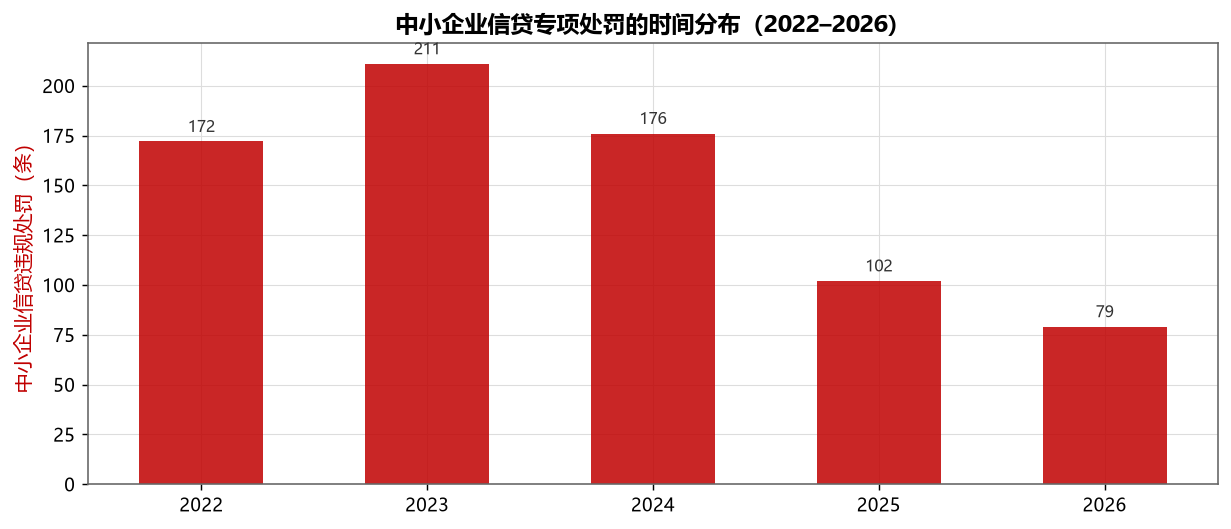

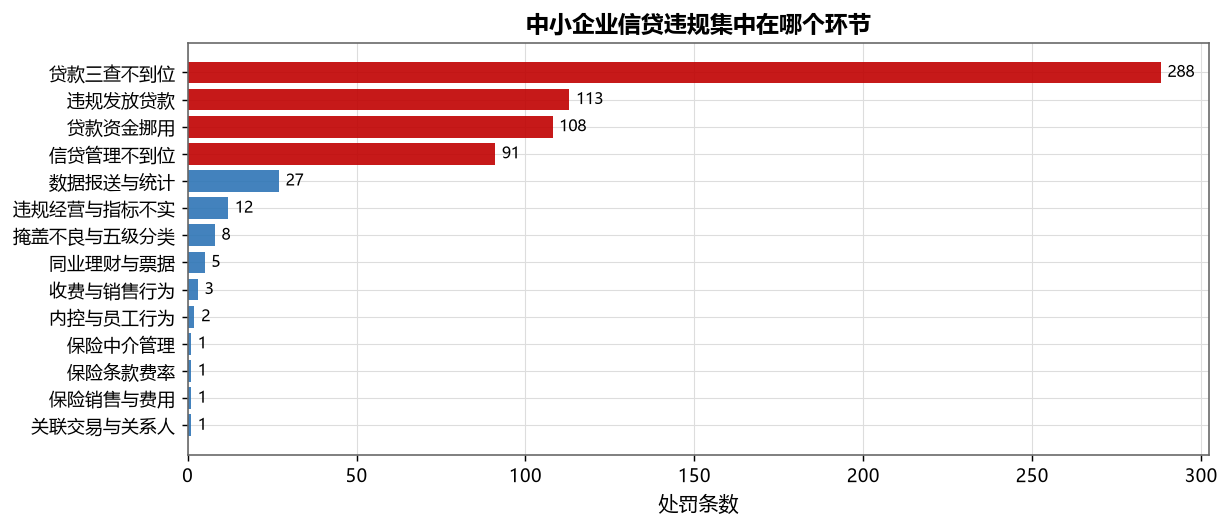

中小企业信贷专项共 **745 条**（占全部处罚 2.0%），最高的是 **贷款三查不到位（288 条）**。

In [5]:
# 第四步：数据可视化——中小企业信贷专项（745 条）
sme_ev = da.sme_credit_events()
ys = sme_ev[sme_ev["年份"] >= 2022].groupby("年份").agg(
    事件数=("docId", "size"),
    金额亿元=("罚没合计万元", lambda s: round(s.sum() / 1e4, 2)))
fig, ax1 = plt.subplots(figsize=(9.6, 4.2))
ax1.bar(ys.index.astype(str), ys["事件数"], color=C_ACCENT, alpha=0.85, width=0.55)
ax1.set_ylabel("中小企业信贷违规处罚（条）", color=C_ACCENT)
annotate_bars(ax1, "{:,.0f}")
ax1.set_title("中小企业信贷专项处罚的时间分布（2022–2026）", fontsize=13)
plt.show()

vc = sme_ev["违规类型"].value_counts()
vc = vc[vc.index != "其他违规"]
fig, ax = plt.subplots(figsize=(9.6, 4.2))
ax.barh(vc.index[::-1], vc.values[::-1],
        color=[C_ACCENT if "贷" in i or "信贷" in i else C_MID for i in vc.index[::-1]], alpha=0.9)
ax.set_xlabel("处罚条数")
ax.set_title("中小企业信贷违规集中在哪个环节", fontsize=13)
for i, v in enumerate(vc.values[::-1]):
    ax.text(v + 2, i, f"{v:,}", va="center", fontsize=9)
savefig(fig, "fig20_sme_violation"); plt.show()

display(Markdown(f"中小企业信贷专项共 **{len(sme_ev):,} 条**（占全部处罚 2.0%），"
                 f"最高的是 **{vc.index[0]}（{vc.iloc[0]:,} 条）**。"))


#### 第二部分：基于大语言模型的自然语言处理
#### 困境 vs 健康：中小企业财务特征差在哪

- **使用数据**：`data/processed/firm_panel.csv` → `da.sme_profile()`（679 家中小企业，含 t+1 困境标签）。
- **处理方式**：按"下一年是否困境"分两组，逐指标做 Mann-Whitney 检验并比较中位数 → 表 + 柱状图。

<div align='center'>
    <img src="汇报材料/Z-score.png" width=500>
</div>


指标,健康组中位数,困境组中位数,差异,p 值,是否显著
资产负债率(%),39.680000,42.720000,3.040000,9.67e-05,***
流动比率,1.940000,1.700000,-0.240000,2.63e-09,***
销售净利率(%),6.690000,-8.870000,-15.560000,2.00e-208,***
销售毛利率(%),30.560000,25.880000,-4.670000,1.00e-14,***
加权ROE(%),8.340000,-7.120000,-15.460000,1.53e-197,***
利息保障倍数,9.420000,-3.620000,-13.040000,4.37e-158,***
总资产周转率,0.660000,0.470000,-0.190000,3.07e-49,***
经营现金流/总负债,0.120000,0.010000,-0.120000,6.24e-59,***
Altman Z′,2.570000,1.510000,-1.060000,1.23e-56,***


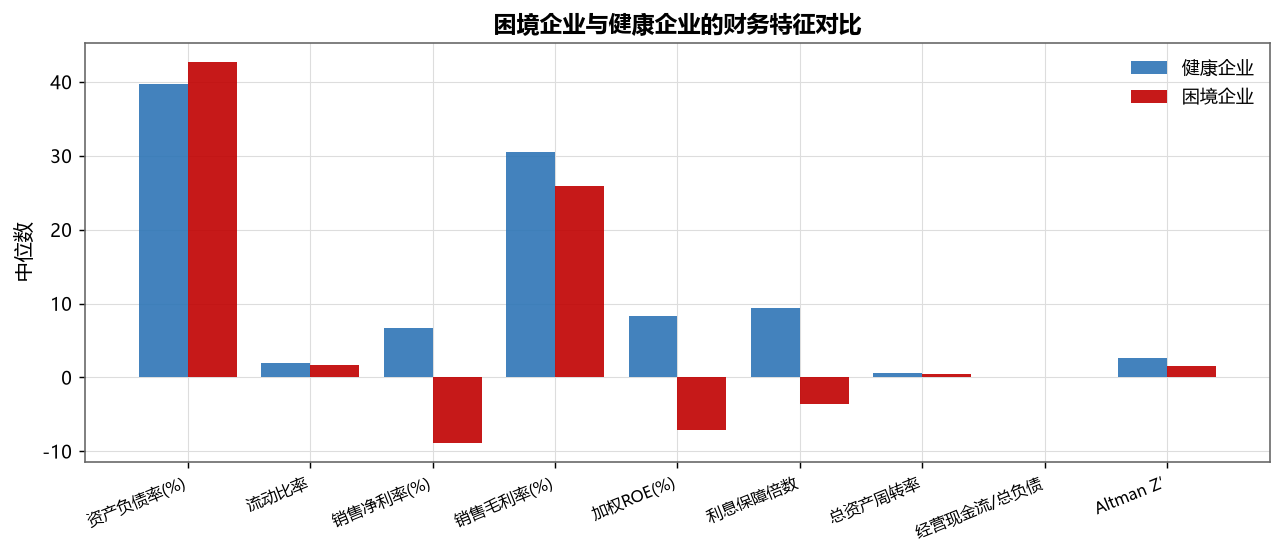

In [6]:
# 困境 vs 健康：财务特征差在哪（企业侧）
sme = da.sme_profile()
g0 = sme[sme["distress"] == 0]
g1 = sme[sme["distress"] == 1]
items = [("ZCFZL", "资产负债率(%)"), ("LD", "流动比率"), ("XSJLL", "销售净利率(%)"),
         ("XSMLL", "销售毛利率(%)"), ("ROEJQ", "加权ROE(%)"),
         ("INTSTCOVRATE", "利息保障倍数"), ("TOAZZL", "总资产周转率"),
         ("ocf_to_liab", "经营现金流/总负债"), ("Z_score", "Altman Z′")]
rows = []
for col, cn in items:
    a, b = g0[col].dropna(), g1[col].dropna()
    if len(a) < 30 or len(b) < 30:
        continue
    p = stats.mannwhitneyu(a, b, alternative="two-sided").pvalue
    rows.append({"指标": cn, "健康组中位数": round(a.median(), 2),
                 "困境组中位数": round(b.median(), 2),
                 "差异": round(b.median() - a.median(), 2),
                 "p 值": f"{p:.2e}" if p < 1e-3 else f"{p:.3f}",
                 "是否显著": "***" if p < 0.01 else ("*" if p < 0.05 else "")})
cmp_tab = pd.DataFrame(rows)
display(cmp_tab.style.hide(axis="index"))

fig, ax = plt.subplots(figsize=(10, 4.4))
x = np.arange(len(cmp_tab))
ax.bar(x - 0.2, cmp_tab["健康组中位数"], 0.4, label="健康企业", color=C_MID, alpha=0.9)
ax.bar(x + 0.2, cmp_tab["困境组中位数"], 0.4, label="困境企业", color=C_ACCENT, alpha=0.9)
ax.set_xticks(x); ax.set_xticklabels(cmp_tab["指标"], rotation=22, ha="right", fontsize=9)
ax.set_ylabel("中位数")
ax.set_title("困境企业与健康企业的财务特征对比", fontsize=13)
ax.legend()
savefig(fig, "fig17_distress_compare"); plt.show()


#### 第三部分：基于XGBoost的中小企业风险系数评估

机器学习算法是机器学习的核心技术之一。

机器学习算法能够对大量的历史信贷数据进行学习和训练，自动提取数据特征，建立风险预测模型。常见的机器学习算法如决策树、随机森林、支持向量机、神经网络等，在信贷风险评估中都有广泛的应用。决策树算法通过对数据进行递归划分，构建树形结构的决策模型，根据不同的特征条件进行决策判断，从而对中小企业的信贷风险进行分类和评估。随机森林则是基于决策树的集成学习算法，通过构建多个决策树并综合它们的预测结果，提高模型的稳定性和准确性。支持向量机通过寻找一个最优的分类超平面，将不同风险类别的数据点分隔开，实现对信贷风险的分类预测。神经网络具有强大的非线性映射能力，能够自动学习数据中的复杂模式和特征，在处理大规模、高维度的数据时表现出独特的优势。深度学习是机器学习的一个分支领域，它通过构建多层神经网络，对数据进行逐层特征提取和抽象，能够更深入地挖掘数据中的潜在信息，进一步提高风险预测的精度。在评估中小企业信贷风险时，深度学习模型可以对企业的财务数据、经营数据、市场数据等进行综合分析，发现数据之间的深层次关联，从而更准确地预测企业的违约风险。

#### 第三部分：基于XGBoost的中小企业风险系数评估
#### 第五步：XGBoost 建模

- **使用数据**：`data/processed/firm_panel.csv` → `dm.build_panel()`（特征 = t 年财务指标；标签 = t+1 是否困境，严格前视）。
- **处理方式**：剔除关键特征缺失过半的样本 → XGBoost 训练 → ROC / AUC / KS → 特征重要度 Top12。

**输出怎么看（这就是"风险评估"）**：

- 模型给每家企业输出一个**违约概率**（0~1）——这就是风险评分；
- **AUC≈0.96、KS≈0.82**：衡量"风险排序准不准"。AUC=0.5 等于瞎猜，越接近 1 越能把高风险企业排到前面；
- **特征重要度**：哪个财务指标对"判定困境"贡献最大，就是贷前调查最该盯的指标。

**特征代码对照**（图/表里的缩写是什么意思）：

| 代码 | 指标含义 |
|---|---|
| ROEJQ | 加权 ROE：每 1 元净资产赚多少（盈利能力） |
| XSJLL | 销售净利率：每 1 元收入最后剩多少净利润 |
| XSMLL | 销售毛利率：扣除成本后每 1 元收入剩多少 |
| ZCFZL | 资产负债率：总负债 ÷ 总资产（杠杆，越高越危险） |
| INTSTCOVRATE | 利息保障倍数：利润够付几倍利息（<1 就危险） |
| ZZCJLL / ROIC | 总资产净利率 / 投入资本回报率（资产赚钱效率） |
| TOAZZL | 总资产周转率：资产一年转几圈（运营效率） |
| ocf_to_liab | 经营现金流 ÷ 总负债（现金回笼能否覆盖债务） |
| x3_ebit_ta | X3：息税前利润 ÷ 总资产（Altman 盈利因子） |
| x2_re_ta | X2：留存收益 ÷ 总资产（多年积累的利润家底） |
| x5_sales_ta | X5：营业收入 ÷ 总资产（资产创收效率） |
| TA_YOYRATIO_PK | 总资产同比增速（扩张速度） |
| 营收/净利同比 | 收入、利润的增长速度 |


样本 **3,381** 条；**XGBoost** AUC **0.9571**，KS **0.8212**

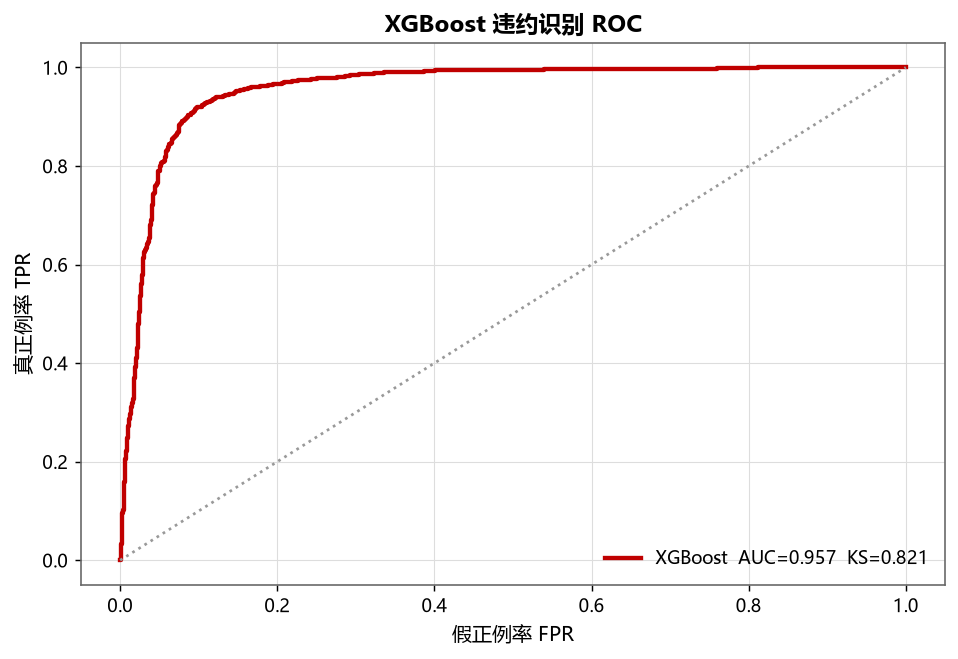

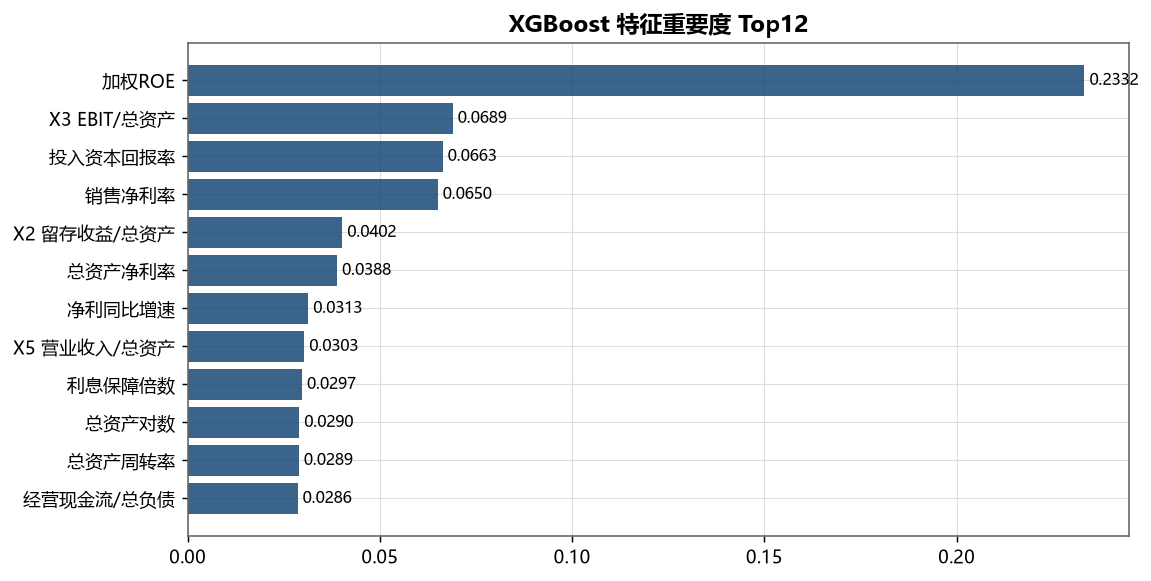

In [7]:
# 第五步：只用 XGBoost 建模——中小企业违约识别
import default_model as dm
from sklearn.metrics import roc_auc_score

panel = dm.build_panel(da.firm_panel())
feat = [c for c in dm.FEATURES if c in panel.columns]
X = panel[feat].replace([np.inf, -np.inf], np.nan)
y = panel["distress"].astype(int)
mask = X.notna().sum(axis=1) > len(feat) * 0.5
Xm, ym = X[mask], y[mask]

gb = dm.fit_gbm(Xm, ym)
s_gb = gb["proba"]
display(Markdown(f"样本 **{len(Xm):,}** 条；**{gb['backend']}** AUC **{roc_auc_score(ym, s_gb):.4f}**，"
                 f"KS **{dm.ks_stat(ym, s_gb):.4f}**"))

fig, ax = plt.subplots(figsize=(7.5, 5.2))
fpr, tpr, _, _ = dm.ks_curve(ym, s_gb)
ax.plot(fpr, tpr, lw=2.4, color=C_ACCENT,
        label=f"{gb['backend']}  AUC={roc_auc_score(ym, s_gb):.3f}  KS={dm.ks_stat(ym, s_gb):.3f}")
ax.plot([0, 1], [0, 1], ls=":", color="#999")
ax.set_xlabel("假正例率 FPR"); ax.set_ylabel("真正例率 TPR")
ax.set_title("XGBoost 违约识别 ROC", fontsize=13)
ax.legend(loc="lower right")
savefig(fig, "fig13_roc"); plt.show()

imp = pd.Series(gb["model"].feature_importances_, index=gb["features"]).sort_values(ascending=False)
top = imp.head(12)[::-1]
labels = [dm.FEATURE_CN.get(k, k) for k in top.index]
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(labels, top.values, color=C_MAIN, alpha=0.88)
ax.set_title("XGBoost 特征重要度 Top12", fontsize=13)
for i, v in enumerate(top.values):
    ax.text(v, i, f" {v:.4f}", va="center", fontsize=8.8)
savefig(fig, "fig15_imp"); plt.show()

FEAT_MEANING = {
    "ROEJQ": "加权ROE：每1元净资产赚多少", "XSJLL": "销售净利率：收入里剩多少净利润",
    "XSMLL": "销售毛利率：扣除成本后剩多少", "ZCFZL": "资产负债率：负债/总资产（杠杆）",
    "INTSTCOVRATE": "利息保障倍数：利润够付几倍利息", "ZZCJLL": "总资产净利率：资产赚钱效率",
    "ROIC": "投入资本回报率", "TOAZZL": "总资产周转率：资产一年转几圈",
    "ocf_to_liab": "经营现金流/总负债", "XJLLB": "现金流量比率",
    "x3_ebit_ta": "X3：息税前利润/总资产", "x2_re_ta": "X2：留存收益/总资产",
    "x5_sales_ta": "X5：营业收入/总资产", "x1_wc_ta": "X1：营运资金/总资产",
    "x4_equity_tl": "X4：账面权益/总负债", "TA_YOYRATIO_PK": "总资产同比增速",
    "TOTALOPERATEREVETZ": "营收同比增速", "PARENTNETPROFITTZ": "净利同比增速",
    "YSZKZZL": "应收账款周转率", "CHZZL": "存货周转率", "log_assets": "总资产对数（规模）",
}



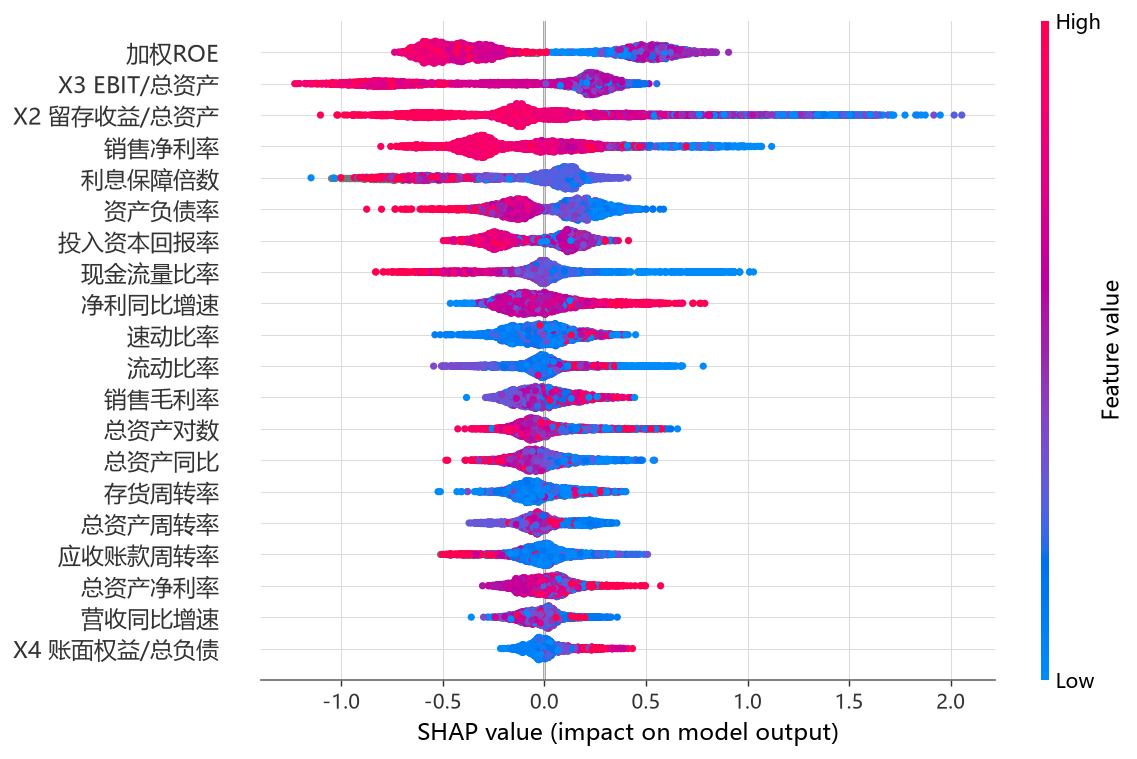

In [16]:
# SHAP 可解释：模型到底靠什么判断违约
import shap

explainer = shap.TreeExplainer(gb["model"])
shap_vals = explainer.shap_values(Xm[gb["features"]])
if isinstance(shap_vals, list):
    shap_vals = shap_vals[1]
feat_cn = [dm.FEATURE_CN.get(k, k) for k in gb["features"]]

# 蜂群图：每个点 = 一个样本；横轴 = 把违约概率推高(+)还是压低(−)；红=特征值高，蓝=低
shap.summary_plot(shap_vals, Xm[gb["features"]], feature_names=feat_cn, show=False)
fig = plt.gcf()
fig.set_size_inches(9.8, 5.6)
savefig(fig, "fig15_shap", tight=False)
plt.show()


#### 第三部分：基于XGBoost的中小企业风险系数评估
#### 评估结论

XGBoost 在 679 家中小企业财务面板（3,381 个公司-年样本）上，用 t 年财务特征预测 t+1 年困境，**AUC = 0.957、KS = 0.821**——风险排序能力接近满分，且 SHAP 与特征重要度两条路径结论一致，可以交叉验证。

模型最依赖的是**盈利能力指标**。加权 ROE 一个指标就占了 **23%** 的重要度，几乎等于第 2 到第 4 名（EBIT/总资产、投入资本回报率、销售净利率）之和；加上留存收益与总资产净利率，**前 6 名全是"赚钱能力"类指标**。与之对照，规模指标只排**第 10**（重要度 0.029），几乎不影响判断——模型看的是"企业赚不赚钱"，不是"企业大不大"。

困境组与健康组的直接对比给出同样的答案：困境企业的销售净利率中位数是 **−8.87%**（健康企业 6.69%）、加权 ROE 是 **−7.12%**（健康企业 8.34%）、利息保障倍数是 **−3.62**（健康企业 9.42）——三项全部显著，且**全部由正转负**；资产负债率与流动比率虽有差异，幅度远小于盈利类指标。

综合起来三点：**盈利与现金流是中小企业信贷风险的第一信号**（净利率、ROE、利息保障倍数全面转负）；**规模不是主因**（监管和银行不该只看企业大小，要看盈利质量与现金覆盖）；**模型结论与信贷专家经验一致**（盈利、现金流、杠杆正是贷前调查的关注点）——XGBoost 可解释、可被监管接受，不是黑箱瞎猜。

<div align='center'>
    <img src="汇报材料/ROE.png" width = 300><img src="汇报材料/困境健康.png" width = 300>
</div>

## 四、结论

### 核心结论回顾

**（一）为什么关注**：中小企业贡献全国 **50% 以上税收、60% 以上 GDP、80% 以上就业**，但融资难、融资贵长期存在——监管与银行都需要一套"看得清、评得准"的中小企业信贷风险评估方法。

**（二）流程上（第二部分）**：中小企业信贷监管必须走完四个环节——**贷前调查**（把企业看清楚）、**贷款审批**（把风险评准确）、**贷款发放**（把手续办合规）、**贷后管理**（把钱收回来）；任一环节失守都会放大风险。

**（三）数据与模型上（第三部分）**：本汇报用真实公开数据走通了"数据挖掘 → 建模"的完整链路：

1. **数据**：东方财富 679 家中小企业财务面板 + 金融监管总局 37,236 条处罚公示，并用大模型对处罚文本做自然语言处理、筛出"中小企业信贷"相关记录；
2. **画像**：中小企业信贷专项 **745 条**，违规集中在"贷款三查不到位"——说明**"看清楚企业"这一环最容易出问题**；
3. **建模**：只用 **XGBoost**——t 年财务特征预测 t+1 年困境，**AUC 0.957、KS 0.821**；
4. **归因**：ROE 一个指标占特征重要度 23%，困境企业的净利率、ROE、利息保障倍数全面转负（全部显著），**规模几乎不重要**。

**（四）一句话总结**：

> 中小企业信贷风险的第一信号是"**盈利与现金流的脆弱**"，而不是规模；
> 可解释的 XGBoost（SHAP + 特征重要度）与信贷专家经验一致，可以作为贷前调查的量化工具。

### 局限

- 标签是"下一年资不抵债或亏损"的**财务困境代理**，不是银行真实违约（微观信贷数据不可得）；
- 样本是新三板/北交所挂牌企业，不等于全部中小企业（缺未挂牌的小微企业）。

<div style="text-align:center;color:#666;padding-top:20px">
汇报结束 · 欢迎提问
</div>